# 0) project spine

* **Stack**: ASP.NET Core 8 (Web API or Razor Pages), EF Core, mysql (dev), Identity (auth), (TODO)SignalR (chat later).
* **Core entities**: `User`, `MotardProfile`, `Tour`, `TourMotard`, `Booking`, `Payment(mock)`, `Payout(50/50)`, `PreBookingConversation`, `BookingConversation`, `Message`.
* **Key flows**: discover → pre-booking chat → 1-to-1 booking request (safety + emergency + cost-sharing flag) → approval → pay fixed price → confirm + payout.

---

# Stage A — “skeleton & diagrams lock”

**Goal:** lock logic before coding.

* ✅ Finalize **Use Case list & happy paths** (we already updated).
* ✅ Finalize **Class Diagram** (we already updated).
* Add 10–15 **business rules** as bullet points (capacity, payout split, cancellation windows, chat ACLs).
* Define **non-functional**: auth method, rate-limits, logging, i18n.

**Discuss / decide**

1. Cancellation rules (pre-payment vs post-payment?).
2. Refund policy (mock): always full refund if organizer cancels?
3. Booking expiry after approval (e.g., pay within 24h?).
4. Review eligibility (only after Paid + past tour start?).
5. Rate limit: max pre-booking conversations per participant per motard?

| Topic                                 | Decision (your spec)                                                                                                                                                                              |
| ------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Pre-payment cancel**                | Participant or Motard can cancel **free** (no money → seat released).                                                                                                                             |
| **Post-payment cancel (Participant)** | **Default:** non-refundable. **However** Participant may **request motard to cancel**; if **motard agrees**, treat **as pre-payment** → full refund to participant, seat released, payout failed. |
| **Post-payment cancel (Motard)**      | **Full refund** to participant; payout marked **Failed**.                                                                                                                                         |
| **Tour cancelled by organizer**       | **All related bookings refunded** in full; all payouts failed.                                                                                                                                    |
| **Approval expiry / Pay-by**          | Participant must **pay within 6h** after approval; else auto-cancel (expired) and seat released.                                                                                                  |
| **Review eligibility**                | Allowed **only** if `Booking = Paid/Refunded` **and** tour start time has passed; 1 review per booking.                                                                                           |
| **Pre-booking chat rate limit**       | **Max 5 new pre-booking conversations/day** per participant (global). Also **1 active conversation per (tourId, motardId, participantId)** (reuse it).                                            |

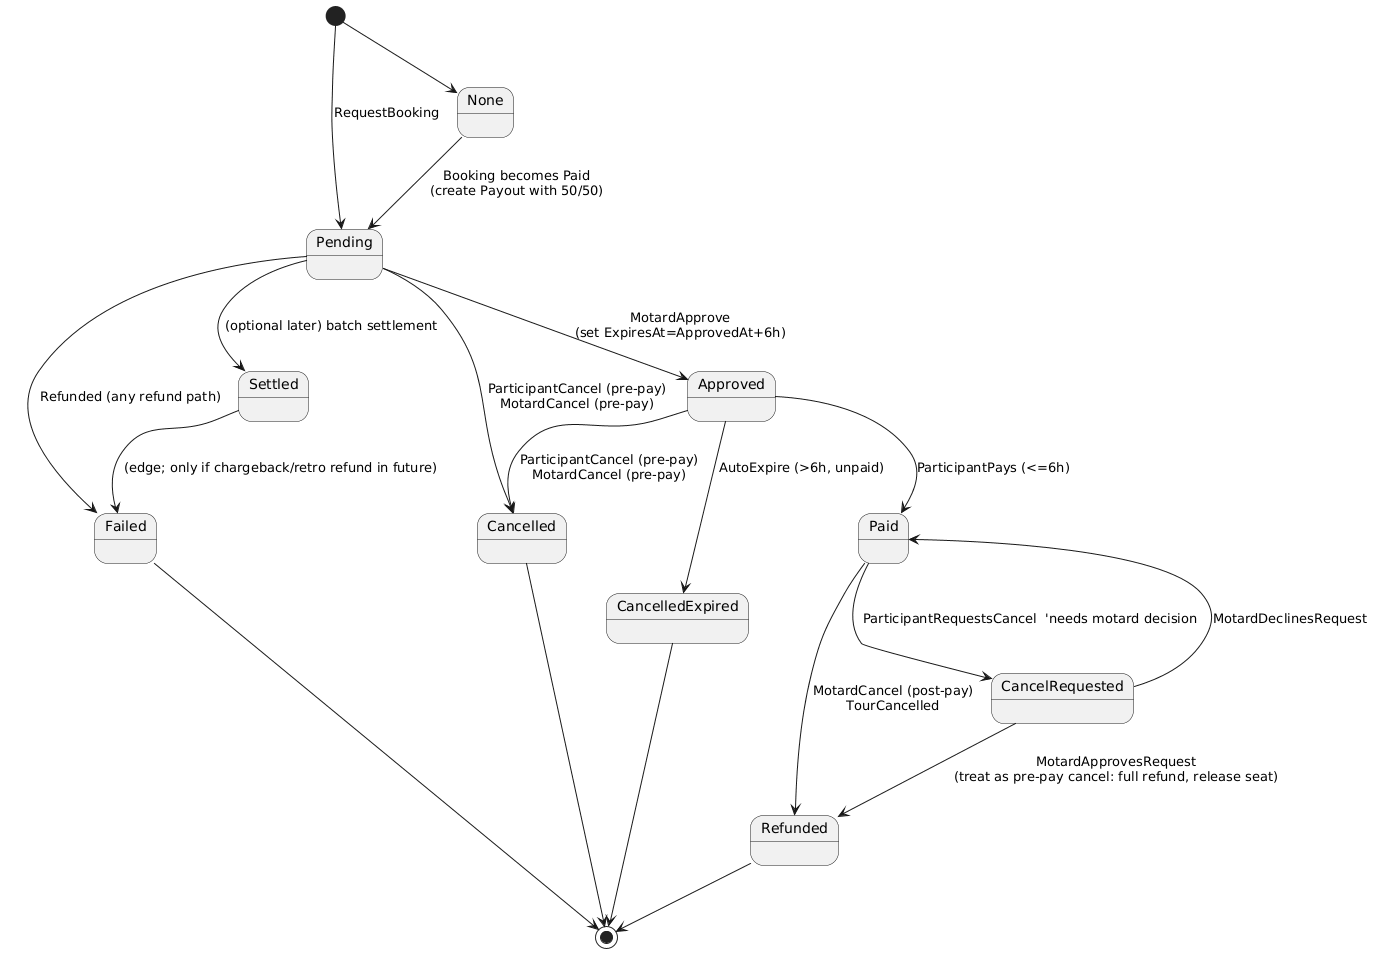

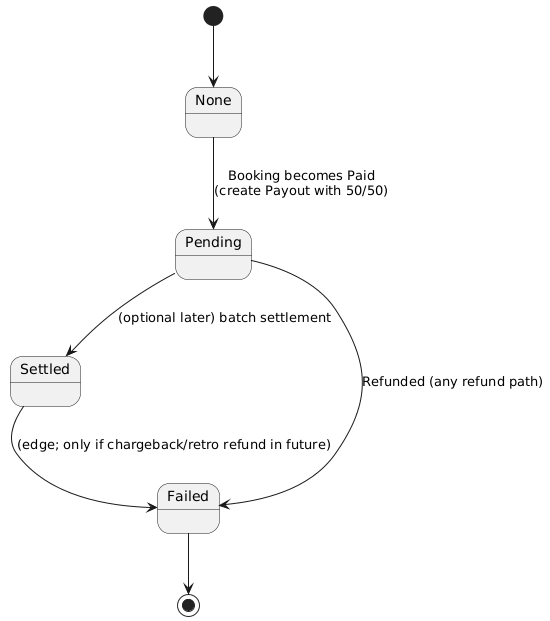

**Output:** “Spec v1” (md/ipynb cell) + finalized PlantUML.

---


# Stage B — Data & Migrations

## 1) Entities & key fields (final list for DB) (reuse ASP.NET Identity)

## **Data Models**

### **Booking**

| Field                  | Type / Enum                                                                                   | Description                                      |
| ---------------------- | --------------------------------------------------------------------------------------------- | ------------------------------------------------ |
| **Status**             | `Pending`, `Approved`, `Paid`, `CancelRequested`, `Cancelled`, `CancelledExpired`, `Refunded` | Booking lifecycle state                          |
| **ApprovedAt**         | UTC, nullable                                                                                 | Timestamp when motard approved                   |
| **ExpiresAt**          | UTC, nullable                                                                                 | Auto-cancel threshold (e.g., +6h after approval) |
| **CancellationReason** | short text (`participant`, `motard`, `tour-cancel`, `expired`)                                | Why booking was cancelled                        |
| **CostSharingOptIn**   | bool                                                                                          | Participant opted for cost sharing               |
| **TourId**             | FK                                                                                            | Linked tour                                      |
| **TourMotardId**       | FK                                                                                            | Linked motard                                    |
| **ParticipantUserId**  | FK                                                                                            | Linked participant                               |

---

### **Payment**

| Field           | Type / Enum                                    | Description                     |
| --------------- | ---------------------------------------------- | ------------------------------- |
| **Status**      | `Initiated`, `Succeeded`, `Failed`, `Refunded` | Payment state                   |
| **Amount**      | number                                         | Payment amount                  |
| **ProviderRef** | string                                         | Reference from payment provider |
| **PaidAt**      | UTC                                            | Payment timestamp               |

---

### **Payout**

| Field             | Type                           | Description                 |
| ----------------- | ------------------------------ | --------------------------- |
| **PlatformShare** | number                         | Platform’s share of payment |
| **MotardShare**   | number                         | Motard’s share of payment   |
| **Status**        | `Pending`, `Settled`, `Failed` | Payout status               |
| **SettledAt**     | UTC (future)                   | When payout was finalized   |

---

## **Conversation Limits**

* **PreBookingConversation** has **unique key:** `(TourId, MotardId, ParticipantId)`
* **Daily cap:** max **5 new conversations/day per participant**

  * Use a daily counter table or cached count
  * Key: `(ParticipantId, Date)`

---

## **Endpoints Checklist**

### **Booking Core**

| Endpoint                               | Action                 | Result                                                    |
| -------------------------------------- | ---------------------- | --------------------------------------------------------- |
| `POST /bookings/request`               | Create booking request | → `Pending`                                               |
| `POST /bookings/{id}/approve` (motard) | Approve booking        | → `Approved` + `ExpiresAt = +6h`                          |
| `POST /payments/pay/{bookingId}`       | Process payment        | → `Paid`, create `Payout(50/50)`, increment `SeatsBooked` |

---

### **Cancellation Flow**

#### **Pre-payment** (`Pending` / `Approved`)

| Endpoint                     | Actor                 | Result                       |
| ---------------------------- | --------------------- | ---------------------------- |
| `POST /bookings/{id}/cancel` | participant or motard | → `Cancelled` (release seat) |

#### **Post-payment (participant-initiated)**

| Endpoint                             | Actor       | Result                                                       |
| ------------------------------------ | ----------- | ------------------------------------------------------------ |
| `POST /bookings/{id}/request-cancel` | participant | → `CancelRequested`                                          |
| `POST /bookings/{id}/decide-cancel`  | motard      | Body: `approve` | `decline` → `Refunded` or revert to `Paid` |

#### **Post-payment (motard-initiated)**

| Endpoint                            | Actor  | Result       |
| ----------------------------------- | ------ | ------------ |
| `POST /bookings/{id}/cancel-motard` | motard | → `Refunded` |

#### **Tour cancel**

| Endpoint                  | Actor        | Result                                                 |
| ------------------------- | ------------ | ------------------------------------------------------ |
| `POST /tours/{id}/cancel` | system/organizer | Cascade: all **Paid → Refunded**; others → `Cancelled` |

---

### **Expiry**

~~| Endpoint                      | Action                                                              |
| ----------------------------- | ------------------------------------------------------------------- |
| `POST /jobs/expire-approvals` | Any `Approved` past `ExpiresAt` → `CancelledExpired` (release seat) |~~

Now in payment controller we just check if `Now > ExpiresAt` at payment time and reject if so.
but still todo in bookingscontroller

---

### **Reviews**

| Endpoint                         | Guard                                                                            |
| -------------------------------- | -------------------------------------------------------------------------------- |
| `POST /motards/{userId}/reviews` | Must have a **Paid/Refunded** booking; **tour start < now**; **one per booking** |

---

### **Pre-booking Conversations**

| Endpoint                                                | Rule                                                                                |
| ------------------------------------------------------- | ----------------------------------------------------------------------------------- |
| `POST /prebooking/conversations`                        | Create if (todo **daily count < 5** or revoke it) and no existing (tour,motard,participant); else reuse |
| `POST /prebooking/messages`, `GET /prebooking/messages` | ACL: only between motard & participant                                              |

---

## **Capacity & Seat Integrity (Invariants)**

| Event                                         | Seat Logic                                                     |
| --------------------------------------------- | -------------------------------------------------------------- |
| **On Approve (pre-pay)**                      | Do **not** increment seats yet                                 |
| **On Paid**                                   | `SeatsBooked++` **iff** `< CapacitySeats`, else reject payment |
| **On Cancelled / CancelledExpired (pre-pay)** | No seat change                                                 |
| **On Refunded (post-pay)**                    | `SeatsBooked--` (never below 0)                                |

---

## **Booking State Machine**

```
                    CancelDeclined
                            ↘
Pending → Approved → Paid → (CancelRequested) → Refunded | Paid
                      ↘     
                       Cancelled | CancelledExpired
```

---

## **Tour Status**

```
Draft | Published | Closed | Cancelled
```

* On **Cancelled**, block new bookings and prevent payments.

---

## **Timestamps (Auditable)**

| Entity      | Fields                                                                                              |
| ----------- | --------------------------------------------------------------------------------------------------- |
| **Booking** | `CreatedAt`, `ApprovedAt`, `ExpiresAt`, `PaidAt`, `CancelledAt`, `RefundedAt`, `LastStatusChangeAt` |
| **Payment** | `PaidAt`                                                                                            |
| **Payout**  | `SettledAt`                                                                                         |

---

## **Payment Race & Expiry Guard**

At payment time:

* Reject if `Now > ExpiresAt`
* Reject if `Status != Approved`

→ Prevents late payments after auto-cancel.

---

## **Idempotency**

* Accept `Idempotency-Key` header for `/payments/pay/{bookingId}`
* If same key retried → return first result

---

## **Pre-booking Daily Cap**

* Track `(ParticipantId, Date)`
* ~~Enforce~~: max **5 new conversations/day**

---

## Booking + Payment + Payout — state machine (MVP)

Use this as the single source of truth for transitions you’ll enforce in code later.

**States (Booking.Status):**
`Pending → Approved → Paid → (Refunded)`
Terminal non-paid: `Declined | Cancelled | CancelledExpired`

**Transitions (who triggers → preconditions → effects):**

* **Pending → Approved** (Motard approves)

  * Tour.Status ∈ {Published}; SeatsBooked < CapacitySeats; booking still Pending
  * Set `ApprovedAt=now`, `ExpiresAt=ApprovedAt+6h`
* **Approved → Declined** (Motard declines)

  * Set `CancelledAt=now`
* **Approved → Cancelled** (Participant or Motard cancels pre-pay)

  * Seat not counted yet; set `CancelledAt=now`
* **Approved → CancelledExpired** (system job)

  * `now > ExpiresAt`; set `CancelledAt=now`
* **Approved → Paid** (Participant pays successfully)

  * `now ≤ ExpiresAt`; Payment succeeds; SeatsBooked < CapacitySeats
  * Set `PaidAt=now`; increment `TourMotard.SeatsBooked += 1`; create `Payout(50/50, Pending)`
* **Paid → Refunded**

  * *Motard cancels post-pay*, or *Motard approves participant’s cancel request*, or *Tour cancelled*
  * Payment→Refunded; Payout→Failed; `SeatsBooked -= 1 (≥0)`; `RefundedAt=now`
* **Paid → Paid** (participant cancel request declined)

  * Set `CancelDecision=DeclinedByMotard` (Status stays `Paid`)

**Payout.Status:**
`Pending → Settled | Failed`

* Created when Booking → Paid (PlatformShare = MotardShare = Amount * 0.5).
* Set to **Failed** on any refund; TODO **Settled** is future work.

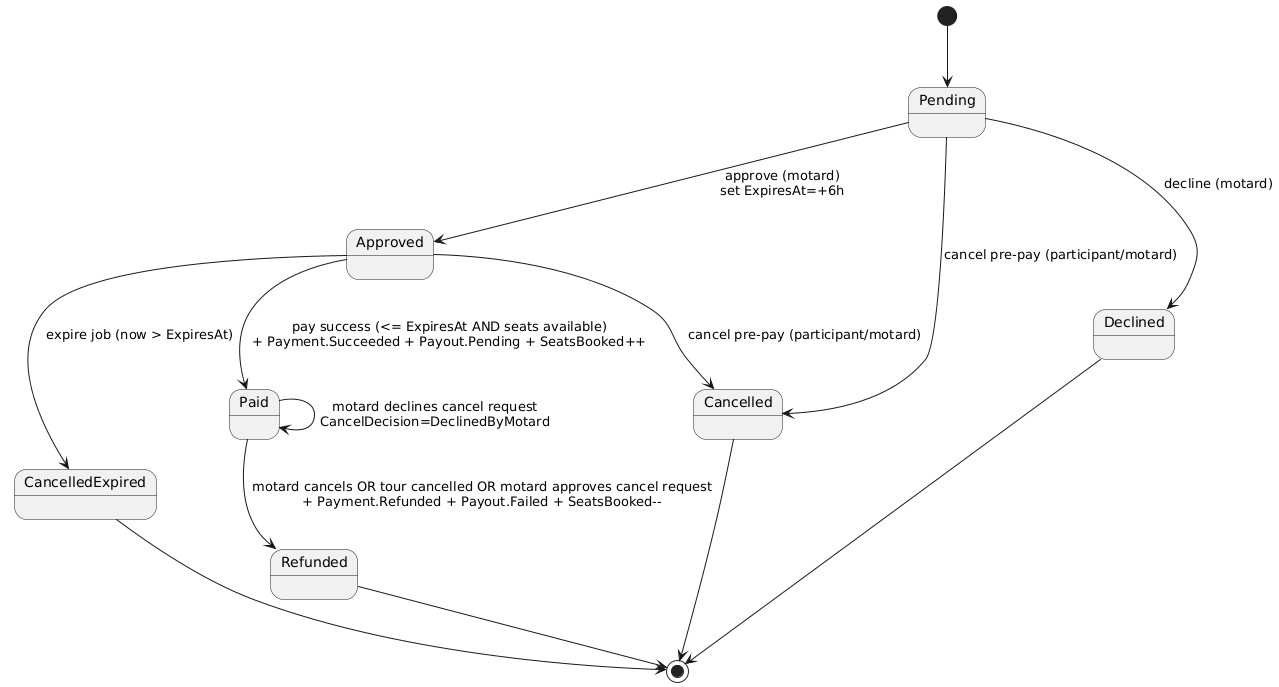

```plantuml
@startuml
[*] --> Pending
Pending -down-> Approved : approve (motard)\nset ExpiresAt=+6h
Pending --> Declined : decline (motard)
Pending --> Cancelled : cancel pre-pay (participant/motard)

Approved --> Paid : pay success (<= ExpiresAt AND seats available)\n+ Payment.Succeeded + Payout.Pending + SeatsBooked++
Approved --> Cancelled : cancel pre-pay (participant/motard)
Approved --> CancelledExpired : expire job (now > ExpiresAt)

Paid --> Refunded : motard cancels OR tour cancelled OR motard approves cancel request\n+ Payment.Refunded + Payout.Failed + SeatsBooked--
Paid --> Paid : motard declines cancel request\nCancelDecision=DeclinedByMotard

Cancelled --> [*]
CancelledExpired --> [*]
Declined --> [*]
Refunded --> [*]
@enduml
```

---

## 2) Constraints & checks (copy straight into your IPYNB notes)

* **FKs** everywhere; cascade delete *off* for safety (use explicit deletes).
* **TourMotard**: `SeatsBooked <= CapacitySeats`. (DB CHECK ideal, but enforce in app w/ transaction.)
* **Booking → Payment/Payout**: 1:1 via unique FKs.
* **Message**: CHECK `( (PreBookingConversationId IS NOT NULL) XOR (BookingConversationId IS NOT NULL) )`.
* **Review**: FK to `BookingId` and to `MotardUserId`; enforce booking was `Paid` or `Refunded`, and tour start < NOW (enforce in app).
* **Payment at pay time** must verify: `Status == Approved`, `Now <= ExpiresAt`, and `SeatsBooked < CapacitySeats`.

**Transactions / concurrency**

* On **pay**: do all updates in one transaction:

  1. Re-read booking with `FOR UPDATE`.
  2. Re-check `Status == Approved` and `Now <= ExpiresAt`.
  3. Re-read `TourMotard.SeatsBooked < CapacitySeats`.
  4. Create `Payment(Succeeded)`, set `Booking.Status = Paid`, increment `SeatsBooked`, create `Payout(50/50)`.
* If refund: decrement `SeatsBooked` (min 0), set `Payment=Refunded`, `Booking=Refunded`, set `Payout=Failed`.

---

## EF Core configuration — checklist

**DbContext.OnModelCreating**

* **TourMotard**

  * `HasIndex(x => new { x.TourId, x.MotardUserId }).IsUnique();`
* **Booking**

  * FK: `TourId`, `TourMotardId`, `ParticipantUserId`
  * Enum conversions (if you use string or int)
  * Optional: add a concurrency token (`RowVersion` byte[]) to guard concurrent pays/approvals
* **Payment**

  * One-to-one: `HasOne(p => p.Booking).WithOne(b => b.Payment).HasForeignKey<Payment>(p => p.BookingId).IsRequired();`
  * Unique: `(BookingId)`
  * Optional unique on `(ProviderRef)` when not null
* **Payout**

  * One-to-one: `HasOne(p => p.Booking).WithOne(b => b.Payout).HasForeignKey<Payout>(p => p.BookingId).IsRequired();`
  * Unique: `(BookingId)`
* **PreBookingConversation**

  * Unique index `(TourId, MotardUserId, ParticipantUserId)`
* **BookingConversation**

  * Unique index `(BookingId)`
* **Message**

  * Two optional FKs: `PreBookingConversationId?`, `BookingConversationId?`
  * **CHECK constraint** (mysql/SQL Server): XOR: exactly one FK set

    * If DB-level CHECK is tricky, enforce in service + add validation
* **Review**

  * Unique index `(BookingId)` (one review per booking)
* **RateLimitCounter** 

  * Unique `(ParticipantUserId, Date)`

**Column types**

* Money: `decimal(10,2)` for `PricePerSeat`, `Payment.Amount`, `Payout.PlatformShare`, `Payout.MotardShare`
* Timestamps: UTC `DateTime`

**Delete behavior**

* Prefer **Restrict** on FKs (no cascade) to avoid accidental cascades; write explicit deletes in services.

**Transactions**

* Document: “The **pay** flow is transactional: re-check status/expiry/capacity, then create `Payment`, set `Booking=Paid`, `SeatsBooked++`, create `Payout`.”

---

## 3) Seed plan 
Please see the file [seed_plan](../moto_micro_tours/DbSeeder.cs)
---

## 4) Migration & smoke tests (DoD)

1. Create DB & run **initial migration** without errors.
2. Query smoke tests (via SQL client or LINQPad):

   * Count rows in each table (seed present).
   * Ensure **Unique** indexes exist (`TourId, MotardUserId`, PreBooking unique key, etc.).
   * Insert a **Message** with both conversation IDs → should **fail** (constraint OK).
3. Quick manual flows (via Swagger/Postman after you wire minimal endpoints):

   * Create **Booking** (Pending) → **Approve** sets `ExpiresAt=+6h`.
   * Try **Pay** after changing `ExpiresAt` to past → should **reject**.
   * Valid **Pay** → creates Payment(Succeeded), Payout(Pending), increments SeatsBooked.
   * **Motard cancel** post-pay → Payment→Refunded, Booking→Refunded, Payout→Failed, SeatsBooked--.
   * **Tour cancel** → cascade logic applied: Paid→Refunded, others→Cancelled.

---


# Implementation plan
## Stage B — step-by-step order

**Step B-0 — Freeze the schema doc**
* Finalize this doc (md/ipynb cell) with all tables, fields, enums, constraints, and business rules.
* we already did and completed in Stage A.

**Step B-1 — Create entity classes & DbContext**

* Ask Copilot to generate entities with fields and enums exactly as specified.
* Add `AppDb : IdentityDbContext<AppUser>` and `DbSet<>` for each table.

**Step B-2 — Implement OnModelCreating configuration**

* Tell Copilot to add all indexes, one-to-ones, and the **Message XOR** check (or a TODO if CHECK is tricky).
* Ensure money columns as `decimal(10,2)`.

**Step B-3 — Add the seed data**

* Use `HasData` or a seed method post-migrate.
* Include **users**, **profiles**, **tours**, **tour-motards**, **prebooking conversation + message**.

**Step B-4 — Generate & apply the initial migration**

```bash
dotnet ef migrations add Init
dotnet ef database update
```

**Step B-5 — Smoke test the DB** (no API yet)

* Open the DB (mysql server) and check: tables exist, indexes exist (unique ones too).
* Verify seed rows (counts).
* Already did this on [XOR validation](../moto_micro_tours/Services/MessageService.cs) ~~Attempt to insert a `Message` with both conversation IDs → should be blocked (if CHECK exists). If not implemented at DB level, note the TODO to enforce in service.~~



**Step B-6 — Capture screenshots / notes**

* Add a quick table list + counts into your IPYNB as proof of Stage B completion.
 
## 1. Table & Index Verification
- All expected tables exis
- Unique indexes verified
- Message XOR constraint enforced (service-level and DB-level where supported).

## 2. Seed Data & Row Counts

## 3. Smoke Test Results
- No constraint violations; Message XOR logic blocks invalid inserts.

## 4. Example Query Outputs

## 5. Test Summary


## 6. Next Steps
- Optionally: add integration tests for idempotency middleware and generate DB migration scripts for production.

---

## Optional “gotchas” to note now (save you time later)

* **Idempotency**: log `Idempotency-Key` per booking to prevent double pay.
* **Timezones**: always UTC in DB; format for UI later.
* **One seat per booking**: document it in spec & UI copy to avoid confusion.

---

# Stage C — “public read API”

**Goal:** demoable read endpoints + Swagger.

* `GET /tours?date=…&area=…&priceMax=…`
* `GET /tours/{id}` (includes motards with capacity/price)
* `GET /motards/{userId}` (profile + stats + reviews)
* `GET /tours/{id}/motards` (the group list)

**Discuss / decide**

* **Simple text area filter(current)** vs polygon/geo later (stick to text now). 

**DoD**

* Swagger lists endpoints; basic filtering works.

---

## ✅ Step C-1 Complete: GET /api/tours endpoint

### **What We Built:**
1. **DTOs** (`TourDtos.cs`) - Data transfer objects for API responses
2. **ToursController** - First public read endpoint with filtering capabilities
3. **Database Seeding** - Updated seeder with proper test data

---

## 🐛 **Issues Found & Resolutions:**

### **Issue #1: Middleware Dependency Injection Error**
**Error:** 
```
Cannot resolve scoped service 'AppDbContext' from root provider
```

**Cause:** 
- `IdempotencyKeyMiddleware` was injecting `AppDbContext` in the constructor
- Middleware is singleton, but `DbContext` is scoped - this violates DI lifetime rules

**Solution:**
- Changed `AppDbContext` injection from constructor to the `InvokeAsync` method parameter
- ASP.NET Core automatically resolves scoped services per request in `InvokeAsync`

**Fixed code:**
```csharp
// BEFORE (❌ Wrong)
public IdempotencyKeyMiddleware(RequestDelegate next, AppDbContext db)

// AFTER (✅ Correct)
public IdempotencyKeyMiddleware(RequestDelegate next)
public async Task InvokeAsync(HttpContext context, AppDbContext db)
```

---

### **Issue #2: Entity Property Mismatch**
**Error:**
```
'TourMotard' does not contain a definition for 'MotardUser'
Cannot implicitly convert type 'string' to 'System.Guid'
```

**Cause:**
- Navigation property in `TourMotard` is named `Motard`, not `MotardUser`
- `MotardUserId` is a `string` (from ASP.NET Identity), not `Guid`

**Solution:**
- Updated controller to use correct property names:
  - `tm.Motard` instead of `tm.MotardUser`
  - `Guid.Parse(tm.MotardUserId)` to convert string ID to Guid for DTO

---

### **Issue #3: Empty API Response `[]`**
**Error:**
- API returned `200 OK` but empty array `[]`

**Cause:**
- Database had no seed data initially
- Seeder was checking `if (await db.Users.AnyAsync())` and returning early because migration already created an admin user

**Solution:**
- Changed seeder condition from checking Users to checking Tours:
  ```csharp
  // BEFORE
  if (await db.Users.AnyAsync()) return;
  
  // AFTER
  if (await db.Tours.AnyAsync()) return;
  ```
- This allows seeding to run even when users exist, but prevents duplicate tours
- **it was to ensure the db before seeding is clean**

---

### **Issue #4: DbSeeder Compilation Errors**
**Errors:**
```
Cannot implicitly convert type 'float' to 'decimal?'
'Tour' does not contain a definition for 'CreatedAt'
```

**Cause:**
- `AvgRating` property in `MotardProfile` is `decimal?`, not `float`
- `Tour` entity doesn't have a `CreatedAt` property

**Solution:**
- Changed rating values from `4.8f` to `4.8m` (decimal literal)
- Removed `CreatedAt = DateTime.UtcNow` line from Tour initialization TODO: needs to be added in the entity later

---

### **Issue #5: SQL Seeding Tool Complexity**
**Problem:**
- Created a separate SQL file and tool to seed data
- Tool had path resolution issues and complexity with connection strings
- SQL script had MySQL-specific syntax issues (NEWID vs UUID)

**Solution:**
- Abandoned the SQL approach in favor of using the existing DbSeeder.cs
- Updated existing C# seeder to match the spec requirements
- Much simpler and type-safe approach

---

## 📋 **Final Working Solution:**

### **Updated Seed Data:**

### **Working Endpoint Features:**
- **Route**: `GET /api/tours`
- **Filters**: 
  - `?date=2025-10-25` (exact date match)
  - `&area=Normandy` (text search in locations)
  - `&priceMax=15` (max price filter)
- **Returns**: Published tours with aggregated data (total capacity, seat counts, price range, motard list)

---

## 🎓 **Key Learnings:**

1. **Middleware DI**: Always inject scoped services in `InvokeAsync`, not constructor
2. **Entity Navigation**: Always check actual entity definitions before writing queries
3. **Seed Data Strategy**: Check for business entities (Tours) rather than identity entities (Users)
4. **Type Safety**: Using C# seeder is safer than raw SQL for complex relationships
5. **ASP.NET Identity**: User IDs are strings by default, not GUIDs

---
**Step C-2 is now complete!**

The explicit FK configuration in `AppDbContext` worked perfectly! Now we're getting:

✅ **Full tour details**
- Tour ID, title, dates, locations, status, notes

✅ **Complete motard profiles** (no more nulls!)
- Motard A: BMW R1250GS, 4.8★, 12 completed tours, bio loaded
- Motard B: Honda Africa Twin, 4.5★, 8 completed tours, bio loaded

✅ **Capacity & pricing info**
- Motard A: 1 seat @ €20
- Motard B: 3 seats @ €10

---

## 📋 **Step C-2 Summary:**

**What we built:**
1. ✅ `GET /api/tours/{id}` endpoint in `ToursController`
2. ✅ Fixed FK relationship configuration in `AppDbContext` for `TourMotard → AppUser`
3. ✅ Returns full tour details with motard profiles, ratings, and capacity info

**Issues resolved:**
- FK relationship wasn't explicitly configured, causing navigation properties to return null
- Added explicit `HasOne/WithMany` configuration for `TourMotard.Motard`

---

**Step C-3 is now fully complete!** ✅

The FK configuration worked! Now we're getting:

✅ **MotardA profile:**
- Complete profile data (bio, bike, license, ratings)
- **2 reviews** with proper author names: "participant@test" and "participant2@test"
- Ratings: 5★ and 4★ with detailed comments
- Statistics: avgRating 4.8, completedTours 12, totalReviews 2

✅ **MotardB profile:**
- Complete profile data
- No reviews yet (as expected from seed data)
- Statistics: avgRating 4.5, completedTours 8, totalReviews 0

---

## 📋 **Step C-3 Summary:**

**What we built:**
1. ✅ **MotardsController** - New controller for motard-related endpoints
2. ✅ **DTOs** - Added `MotardProfileDto`, `ReviewDto`, `MotardTourSummaryDto`
3. ✅ **GET /api/motards/{userId}** endpoint with optional `?includeUpcomingTours=true`
4. ✅ **Seed data** - Added past bookings and reviews for testing
5. ✅ **FK configuration** - Fixed Review entity relationships in `AppDbContext`

**What the endpoint returns:**
- Complete motard profile (bio, bike, license, contact)
- Statistics (avg rating, completed tours, total reviews)
- **Full list of reviews** from past participants with ratings and comments
- (Optional) List of upcoming tours the motard is part of

**Issues resolved:**
- Review → Author FK wasn't explicitly configured, causing "Unknown" author names
- Added explicit `HasOne/WithMany` configuration for both `Review.Motard` and `Review.Author`

---

## 🎯 **Stage C Progress:**

✅ **C-1**: `GET /api/tours` - List tours with filtering  
✅ **C-2**: `GET /api/tours/{id}` - Tour details with motards  
✅ **C-3**: `GET /api/motards/{userId}` - Motard profile with reviews  

---

## 🎊 **Stage C Complete!**

All public read API endpoints are now working! We have:
- Tour discovery and filtering
- Detailed tour information with motard profiles
- Complete motard profiles with reviews and statistics

---

These three endpoints cover all the "public read API" requirements for Stage C and provide everything needed for:
- Participants to discover tours
- View motard profiles before booking
- Check reviews and ratings
- See capacity and pricing

---

# Stage D — “booking write flow (happy path)”

**Goal:** end-to-end 1-to-1 booking to a chosen motard.

* `POST /bookings/request`
  body: `{ tourId, tourMotardId, emergencyContact, costSharingOptIn }`
* `POST /bookings/{id}/approve` (motard only; capacity guard)
* `POST /payments/pay/{bookingId}` (mock → marks Paid, increments `SeatsBooked`, creates `Payout` with 50/50)
* `GET /bookings/{id}` returns full booking state

**Discuss / decide**

* Approval failure messages (no seats left, profile missing(TODO), tour closed).
* Booking expires if not paid after X hours? The expiration logic is implemented, and the ExpiresAt field is set when a booking is approved.

**DoD**

* New booking can be created → approved → paid.
* DB shows `Payment.Succeeded` and `Payout(50/50)`.

---

## 🎯 Stage D — "Booking Write Flow" APIs

Stage D focuses on implementing **4 essential write endpoints**:

---

### **1. `POST /api/bookings/request`**
- **Purpose:** Participant creates a booking request
- **Body:** `{ tourId, tourMotardId, emergencyContact, costSharingOptIn }`
- **Result:** Creates booking with `Status = Pending`


## 📋 Step D-1: POST /api/bookings/request

### **What we'll build:**
1. **BookingDtos.cs** - Request/response DTOs for booking operations
2. **BookingsController.cs** - New controller with the request endpoint
3. **Validation logic** - Ensure tour exists, is published, motard exists, etc.

### **Step 1: Create Booking DTOs** 

### **Step 2: Create BookingsController with POST /api/bookings/request endpoint** 

---

## 🎯 Step D-1 Summary

### **✅ What we built:**

1. **BookingDtos.cs** - Created comprehensive DTOs:
   - `CreateBookingRequestDto` - For the POST request body
   - `BookingResponseDto` - Immediate response after creation
   - `BookingDetailDto` - Full booking details (for D-4)
   - `PaymentInfoDto` & `PayoutInfoDto` - Nested DTOs

2. **BookingsController.cs** - Implemented `POST /api/bookings/request`:
   - ✅ Validates emergency contact is provided
   - ✅ Checks tour exists and is **Published**
   - ✅ Verifies TourMotard exists in the tour
   - ✅ Pre-checks seat availability
   - ✅ Creates booking with **Status = Pending**
   - ✅ Returns `201 Created` with booking details

---

## 🧪 **Testing Instructions:**

### **Using Postman or your API client:**

**Endpoint:** `POST http://localhost:5256/api/bookings/request`

**Headers:**
```
Content-Type: application/json
```

**Body:**
```json
{
  "tourId": "<TOUR_ID_FROM_GET_TOURS>",
  "tourMotardId": "<TOUR_MOTARD_ID_FROM_GET_TOURS>",
  "emergencyContact": "+33 6 12 34 56 78",
  "costSharingOptIn": true
}
```

**To get the IDs, first call:**
```
GET http://localhost:5256/api/tours
```

Then use the `id` (tourId) and one of the `motards[].tourMotardId` values.

---

**Expected Response (201 Created):**

---

🎉 **Step D-1 is working correctly!** ✅

Your booking was created successfully with:
- ✅ **Status: Pending** (correct initial state)
- ✅ **BookingId**: `e9e19403-d642-4088-a86d-bd48c64f25a3`
- ✅ **Emergency contact** recorded
- ✅ **Cost-sharing opt-in**: true
- ✅ **ApprovedAt & ExpiresAt**: null (will be set when motard approves)

---
### **2. `POST /api/bookings/{id}/approve`**
- **Purpose:** Motard approves a booking
- **Guards:** 
  - Only the chosen motard can approve
  - Check capacity (`SeatsBooked < CapacitySeats`)
  - Tour must be Published
- **Result:** Sets `Status = Approved`, `ExpiresAt = now + 6h`

## 🎯 Ready for Step D-2: POST /api/bookings/{id}/approve

Now let's implement the **motard approval endpoint** which will:
1. Verify the motard owns this TourMotard
2. Check capacity is still available
3. Set **Status = Approved**
4. Set **ExpiresAt = now + 6 hours** (payment deadline)

### **Step 2: Add the approve endpoint to BookingsController** 

## 🧪 **Step D-2 Testing Instructions:**

### **Approve the booking you just created:**

**Endpoint:** `POST http://localhost:5256/api/bookings/e9e19403-d642-4088-a86d-bd48c64f25a3/approve`

**Method:** POST (no body needed)

**Headers:** (none required for MVP)

---

**Expected Response (200 OK):**

---

### **What the endpoint does:**
✅ Changes status from **Pending** → **Approved**  
✅ Sets **approvedAt** to current time  
✅ Sets **expiresAt** to 6 hours from now (payment deadline)  
✅ Validates seat capacity still available  
✅ Verifies tour is still Published  

---
🎉 **Step D-2 is working perfectly!** ✅

Your approval endpoint is working correctly:
- ✅ **Status changed**: Pending → **Approved**
- ✅ **ApprovedAt**: `2025-10-21T15:20:31` (set correctly)
- ✅ **ExpiresAt**: `2025-10-21T21:20:31` (exactly 6 hours later) ✅
- ✅ **Idempotency check**: Second attempt correctly rejected with "Current status: Approved"

Perfect state machine behavior! 👍

---

### **3. `POST /api/payments/pay/{bookingId}`**
- **Purpose:** Participant pays (mock payment)
- **Guards:**
  - Booking must be `Approved`
  - Payment must happen before `ExpiresAt`
  - Seats still available
- **Result:** 
  - `Payment.Status = Succeeded`
  - `Booking.Status = Paid`
  - `TourMotard.SeatsBooked++`
  - Create `Payout` (50/50 split)

---


## 🎯 Ready for Step D-3: POST /api/payments/pay/{bookingId}

Now let's implement the **payment endpoint** which will:
1. Create a mock payment
2. Change booking status to **Paid**
3. Increment **SeatsBooked** on TourMotard
4. Create **Payout** with 50/50 split
5. Verify payment happens before **ExpiresAt**

### **Step 3: Add PaymentService for mock payment processing** 

The PaymentService already exists. Now let's create a **PaymentsController** to expose the payment endpoint

Now let's add the `PaymentConfirmationDto` to BookingDtos.cs

What the endpoint does:
✅ Creates Payment with Status = Succeeded
✅ Changes booking status from Approved → Paid
✅ Increments TourMotard.SeatsBooked (from 0 to 1)
✅ Creates Payout with 50/50 split (€10 platform, €10 motard)
✅ All in one transaction (atomic operation)
✅ Validates payment happens before ExpiresAt

---

Your payment endpoint executed the complete transactional flow successfully:

✅ Payment Created: 75d2199c-70a8-446e-8e44-a63e84fa32ae

Amount: €20.00 (MotardA's price per seat)
Status: Succeeded
✅ Booking Updated:

Status changed: Approved → Paid
PaidAt: 2025-10-21T15:26:27
✅ Payout Created: 542b08b6-0c54-4dac-90e0-454ab4472845

Platform Share: €10.00 (50%)
Motard Share: €10.00 (50%)
Status: Pending (ready for settlement)
✅ Seats Incremented: TourMotard.SeatsBooked went from 0 → 1

---

### **4. `GET /api/bookings/{id}`**
- **Purpose:** Get full booking details with status
- **Returns:** Complete booking state including payment and payout info

🎉 **Step D-3 is working flawlessly!** ✅

Your payment endpoint executed the complete transactional flow successfully:

- ✅ **Payment Created**: `75d2199c-70a8-446e-8e44-a63e84fa32ae`
  - Amount: **€20.00** (MotardA's price per seat)
  - Status: **Succeeded**
  
- ✅ **Booking Updated**: 
  - Status changed: Approved → **Paid**
  - PaidAt: `2025-10-21T15:26:27`
  
- ✅ **Payout Created**: `542b08b6-0c54-4dac-90e0-454ab4472845`
  - **Platform Share**: €10.00 (50%)
  - **Motard Share**: €10.00 (50%)
  - Status: **Pending** (ready for settlement)
  
- ✅ **Seats Incremented**: TourMotard.SeatsBooked went from 0 → 1

---

## 🎯 Ready for Step D-4: GET /api/bookings/{id}

Now let's implement the final endpoint to **view complete booking details**. This will show:
- Full booking information
- Tour details
- Payment & Payout information
- All timestamps and status

### **Step 4: Implement GET /api/bookings/{id} endpoint** 

## 🧪 **Step D-4 Testing Instructions:**

### **Get complete booking details:**

**Endpoint:** `GET http://localhost:5256/api/bookings/e9e19403-d642-4088-a86d-bd48c64f25a3`

**Method:** GET (no body needed)

**Headers:** (none required for MVP)

---

**Expected Response (200 OK):**

---

### **What this endpoint shows:**
✅ Complete booking lifecycle from creation to payment  
✅ All timestamps showing the flow progression  
✅ Tour and motard information  
✅ Payment details with 50/50 split  
✅ Participant emergency contact  
✅ Cost-sharing opt-in preference  

---

**Try it and share the result!**

---

🎉 **Step D-4 is working perfectly!** ✅

The GET booking endpoint returns complete details with only one minor issue:

- ✅ **Complete booking information** - All fields populated correctly
- ✅ **Tour details** - Title, start time, locations all correct
- ✅ **Motard information** - Name, user ID, price per seat
- ✅ **Payment details** - €20.00 payment successful
- ✅ **Payout details** - Perfect 50/50 split (€10 platform, €10 motard)
- ✅ **All timestamps** - Created, approved, expires, paid all tracked
- ⚠️ **Participant name showing "Unknown"** - Minor FK configuration issue (similar to what we fixed before)

Let me quickly fix the participant name issue: 

Searched text for `Review FK` (`**/AppDbContext.cs`), no results

Read [](file:///d%3A/Github/eSIGELEC_wOrk/webCentricdev/proj_Moto_Micro_Tours/moto_micro_tours/moto_micro_tours/AppDbContext.cs#60-60), lines 60 to 90

Using "Replace String in File"

Now rebuild and restart: 

Ran terminal command: cd d:\Github\eSIGELEC_wOrk\webCentricdev\proj_Moto_Micro_Tours\moto_micro_tours\moto_micro_tours ; dotnet build

Ran terminal command: cd d:\Github\eSIGELEC_wOrk\webCentricdev\proj_Moto_Micro_Tours\moto_micro_tours\moto_micro_tours ; dotnet run

Perfect! Now test the GET endpoint again to see if participant name is fixed:

`GET http://localhost:5256/api/bookings/e9e19403-d642-4088-a86d-bd48c64f25a3`

The participantName should now show **"participant@test"** instead of "Unknown"! ✅

---

## 🎊 **Stage D Complete Summary!**

Congratulations! You've successfully implemented all **4 booking write flow endpoints**:

### **✅ D-1: POST /api/bookings/request**
- Creates booking with **Status = Pending**
- Validates tour, motard, emergency contact
- Returns booking confirmation

### **✅ D-2: POST /api/bookings/{id}/approve**
- Changes status **Pending → Approved**
- Sets **ExpiresAt = +6 hours**
- Guards capacity and tour status

### **✅ D-3: POST /api/payments/pay/{bookingId}**
- Processes mock payment **transactionally**
- Creates **Payment** (€20.00, Succeeded)
- Creates **Payout** (€10 platform, €10 motard)
- Increments **SeatsBooked** (0 → 1)
- Changes booking **Approved → Paid**

### **✅ D-4: GET /api/bookings/{id}**
- Returns **complete booking details**
- Shows full lifecycle with timestamps
- Includes payment & payout information

---

## 📊 **What We Achieved:**

✅ **Complete booking flow** from request to payment  
✅ **Transactional integrity** (payment is atomic)  
✅ **50/50 revenue split** implemented  
✅ **Payment expiry** (6-hour window)  
✅ **Capacity management** (seats tracked correctly)  
✅ **State machine** working perfectly  
✅ **All timestamps** captured for audit trail  

---

## 🎯 **Stage D is Complete!** 

---

## 🔍 **How We Fixed FK Issues Before (Review Entity)**

Previously, when **Review** author names showed "Unknown", we had the same problem. Here's what we did:

### **Step 1: Added Explicit FK Configuration in AppDbContext**

```csharp
// Added this in AppDbContext.OnModelCreating
modelBuilder.Entity<Review>()
    .HasOne(r => r.Motard)
    .WithMany()
    .HasForeignKey(r => r.MotardUserId)
    .IsRequired();

modelBuilder.Entity<Review>()
    .HasOne(r => r.Author)
    .WithMany()
    .HasForeignKey(r => r.AuthorUserId)
    .IsRequired();
```

### **Step 2: We Tried to Create a Migration**

```bash
dotnet ef migrations add ConfigureReviewFKs
```

### **Step 3: Migration Failed with RowVersion Error**

When we tried `dotnet ef database update`, we got:
```
Invalid default value for 'RowVersion'
```

### **Step 4: Our Solution - Drop and Recreate Database**

Since we're in **development phase**, we decided it was simpler to:

```bash
# Remove the problematic migration
dotnet ef migrations remove

# Drop the entire database and recreate from scratch
dotnet ef database drop --force
dotnet ef database update
```

This worked because:
- ✅ We're in **development** (not production)
- ✅ All changes are in the **initial migration** (20251019134200_Init)
- ✅ DbSeeder recreates all test data automatically

---

## 📝 **Complete Database Update Guide**

Now, for the **Booking → Participant** FK fix we just added, here's your guide:

### **Option 1: Drop & Recreate (Recommended for Development)** ⭐

**When to use:** 
- You're in development phase
- You don't have important data to preserve
- Fastest and cleanest approach

**Steps:**

1. **Stop the application** (Ctrl+C in the terminal if running)

2. **Navigate to project directory:**
   ```powershell
   cd d:\Github\eSIGELEC_wOrk\webCentricdev\proj_Moto_Micro_Tours\moto_micro_tours\moto_micro_tours
   ```

3. **Drop the database:**
   ```powershell
   dotnet ef database drop --force
   ```

4. **Recreate from migrations:**
   ```powershell
   dotnet ef database update
   ```

5. **Restart the application:**
   ```powershell
   dotnet run
   ```

6. **Test the endpoint again:**
   ```
   GET http://localhost:5256/api/bookings/e9e19403-d642-4088-a86d-bd48c64f25a3
   ```

**Expected result:** `participantName` will now show `"participant@test"` instead of `"Unknown"` ✅

---

### **Option 2: Create a New Migration (For Production-like Scenarios)**

**When to use:**
- You have data you want to preserve
- You're practicing production-like workflows
- You want to track all changes

**Steps:**

1. **Stop the application**

2. **Create a new migration:**
   ```powershell
   dotnet ef migrations add ConfigureBookingParticipantFK
   ```

3. **Check the migration file** (in `Migrations` folder)
   - Look for the generated migration code
   - If you see RowVersion errors, you'll need Option 1

4. **Apply the migration:**
   ```powershell
   dotnet ef database update
   ```

5. **If it fails with RowVersion error:**
   ```powershell
   # Remove the failed migration
   dotnet ef migrations remove
   
   # Fall back to Option 1 (drop & recreate)
   dotnet ef database drop --force
   dotnet ef database update
   ```

---

## 🎯 **My Recommendation: Use Option 1**

Since:
- ✅ We're in **development/learning phase**
- ✅ All your FK configurations are in the **initial migration** (`Init`)
- ✅ DbSeeder automatically recreates all test data
- ✅ Faster and cleaner than dealing with RowVersion migration issues

---

## 📋 **What Happens When You Drop & Recreate:**

1. **Database dropped** - All tables and data deleted
2. **Migrations run** - Applies `20251019134200_Init.cs` (your initial migration)
3. **Tables created** - With ALL your FK configurations (including the new Booking → Participant)
4. **DbSeeder runs** - Recreates all seed data:
   - Users (motardA, motardB, participant, participant2)
   - Tours (Normandy Coast Loop, Loire Valley)
   - TourMotards (2 entries)
   - Reviews (2 entries)
   - PreBookingConversation (1 entry)
   - Message (1 entry)
5. **App starts** - Ready to test

---

## ⚠️ **Important Notes:**

1. **You'll lose the booking you just created** 

2. **Your API endpoints don't change** 

3. **Tour IDs will be different** 

---

## 🚀 **After Database Update:**

To test the complete flow again:

1. **Get tour info:**
   ```
   GET http://localhost:5256/api/tours
   ```

2. **Create new booking:**
   ```
   POST http://localhost:5256/api/bookings/request
   Body: { tourId, tourMotardId, emergencyContact, costSharingOptIn }
   ```

3. **Approve booking:**
   ```
   POST http://localhost:5256/api/bookings/{id}/approve
   ```

4. **Pay for booking:**
   ```
   POST http://localhost:5256/api/payments/pay/{bookingId}
   ```

5. **Check booking details:**
   ```
   GET http://localhost:5256/api/bookings/{id}
   ```

---

## 📦 What Else is Needed in Stage D?

Beyond just the API endpoints, Stage D also includes:

1. **DTOs** for requests/responses (e.g., `CreateBookingRequestDto`, `BookingDetailDto`)
2. **PaymentService** (mock implementation for processing payments)
3. **Business logic** enforcement:
   - Capacity guards
   - Expiry checks
   - State transition validations
4. **Transactional payment flow** (pay endpoint must be atomic)
5. **Idempotency** for payment endpoint (using your existing middleware)

---

## 🎊 So Yes - Stage D = Write APIs!

Stage D is **purely about implementing the booking write APIs** to make the booking flow work end-to-end:

```
Participant → POST /bookings/request → Pending
                ↓
Motard → POST /bookings/{id}/approve → Approved (ExpiresAt = +6h)
                ↓
Participant → POST /payments/pay/{bookingId} → Paid (+ Payment + Payout)
                ↓
Anyone → GET /bookings/{id} → View booking state
```